<a href="https://colab.research.google.com/github/fwitschel/ResponsibleAI/blob/main/notebooks/XAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os

# Execute this code only if in colab
if 'COLAB_GPU' in os.environ:
  print("Executing in Colab!")
  # Cloning GitHub repository
  !git clone https://github.com/fwitschel/ResponsibleAI.git
  %cd ResponsibleAI

Executing in Colab!
Cloning into 'HCIBM'...
remote: Enumerating objects: 97, done.
remote: Counting objects: 100% (97/97), done.
remote: Compressing objects: 100% (90/90), done.
remote: Total 97 (delta 16), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (97/97), 911.83 KiB | 4.11 MiB/s, done.
Resolving deltas: 100% (16/16), done.
/content/HCIBM


In [2]:
!pip install lime
import shap
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import lime
import lime.lime_tabular
from xgboost import XGBClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn import tree

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 4.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=20bd784a47adf9dc1d4d706a18f14c4cf3792f93704081d820813c07061aad95
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [5]:
# load the data
data = pd.read_csv('/content/ResponsibleAI/data/H1.csv')

# remove the columns corresponding to other complications that we do not want to predict
data = data.drop('DepositType', axis=1)
data = data.drop('ReservationStatus', axis=1)
data = data.drop('ReservationStatusDate', axis=1)
data = data.drop('AssignedRoomType', axis=1)
data = data.drop('BookingChanges', axis=1)
data = data.drop('DaysInWaitingList', axis=1)
data = data.drop('ArrivalDateYear', axis=1)
data = data.drop('Country', axis=1)
data = data.drop('Agent', axis=1)
data = data.drop('Company', axis=1)
data = data.fillna(0)

X = data.drop('IsCanceled', axis=1)
#one_hot_X = pd.get_dummies(X)
y = data.IsCanceled

# mark categorical variables as categorical
cat_cols = X.select_dtypes(include='object').columns
X[cat_cols] = X[cat_cols].astype('category')

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
model = XGBClassifier(enable_categorical=True)
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [31]:
j = 0
k = 0
thresh = 0.8

# find an example where the prediction is 1:
preds = model.predict_proba(X_test)
for i in range(42):
    if (preds[i])[0]>thresh:
        j = i
    if (preds[i])[1]>thresh:
        k = i
print("prediction for instance", j, "in test data:", model.predict_proba(X_test)[j])
print("prediction for instance", k, "in test data:", model.predict_proba(X_test)[k])

prediction for instance 40 in test data: [0.862523   0.13747698]
prediction for instance 38 in test data: [0.08157647 0.91842353]


In [32]:
# Fits the explainer
explainer = shap.TreeExplainer(model)
# Calculates the SHAP values - may take some time
shap_values = explainer.shap_values(X_test)

SHAP waterfall plot for instance j (index: 40):


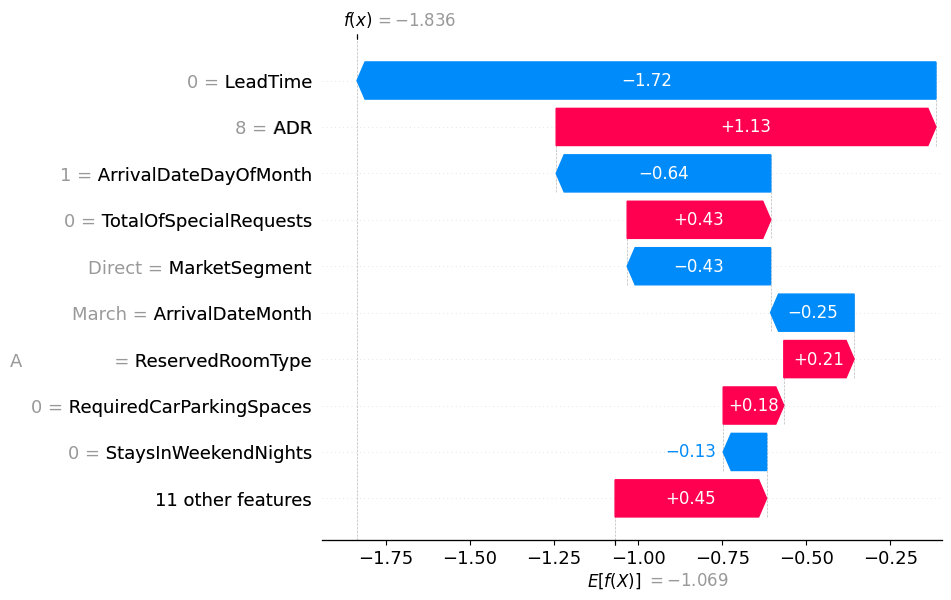


SHAP waterfall plot for instance k (index: 38):


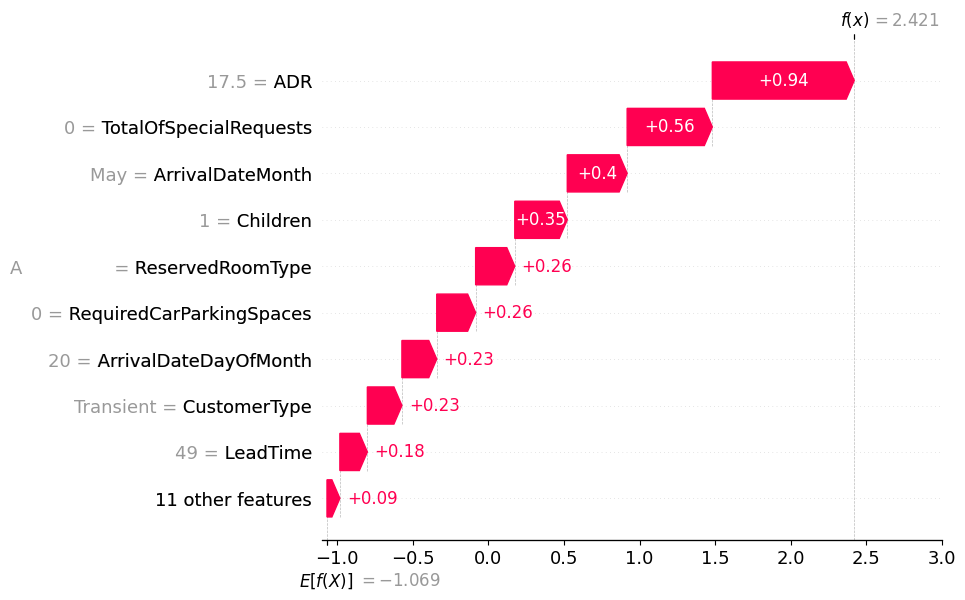

In [33]:
# Calculate SHAP values for the test set, producing Explanation objects
shap_values_explanation = explainer(X_test)

# Make SHAP waterfall plots for instances j and k
print(f"SHAP waterfall plot for instance j (index: {j}):")
shap.plots.waterfall(shap_values_explanation[j])

print(f"\nSHAP waterfall plot for instance k (index: {k}):")
shap.plots.waterfall(shap_values_explanation[k])

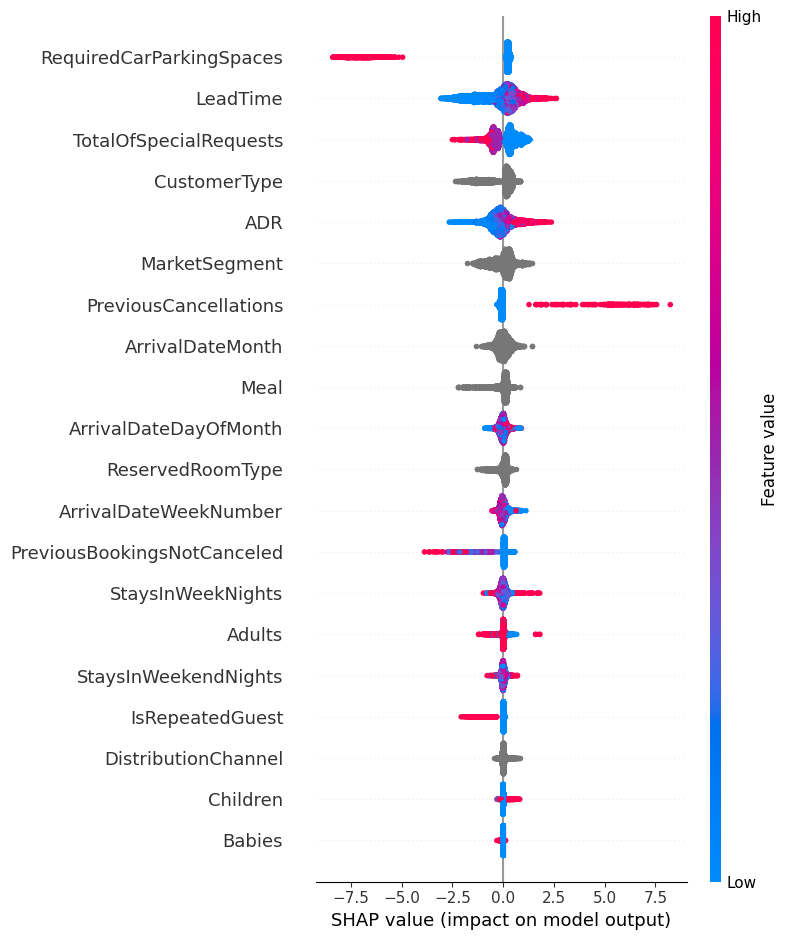

In [34]:
shap.summary_plot(shap_values, X_test)

Index(['LeadTime', 'ArrivalDateMonth', 'ArrivalDateWeekNumber',
       'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights',
       'Adults', 'Children', 'Babies', 'Meal', 'MarketSegment',
       'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations',
       'PreviousBookingsNotCanceled', 'ReservedRoomType', 'CustomerType',
       'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests'],
      dtype='object')


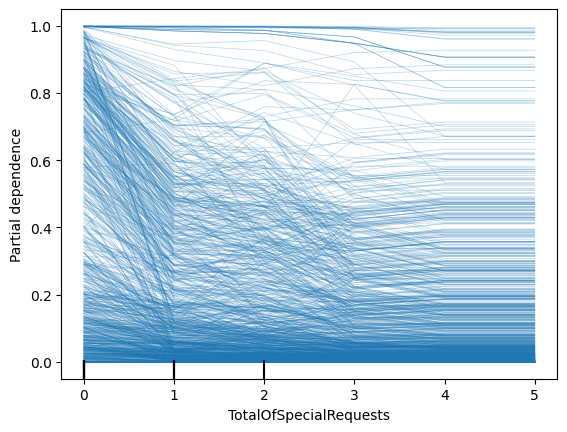

In [35]:
# select a feature, then create an individual conditional expectation plot
# (using PDP plot, with kind = "individual")
print(X_test.columns)
features = [19]
PartialDependenceDisplay.from_estimator(model, X_test, features, kind='individual')

In [36]:
# --- Prepare data for LIME ---

# Make numerical copies for LIME
X_train_lime = X_train.copy()
X_test_lime = X_test.copy()

categorical_features = []
categorical_names = {}

for col in cat_cols:
    col_idx = X_train.columns.get_loc(col)
    categorical_features.append(col_idx)

    # Get the categories already defined in the pandas categorical column
    categories = list(X_train[col].cat.categories)
    categorical_names[col_idx] = categories

    # Replace categories by 0, 1, 2, ... for LIME
    X_train_lime[col] = X_train[col].cat.codes
    X_test_lime[col] = X_test[col].cat.codes


# LIME will call this function with its numerical representation.
# Convert category codes back into pandas categorical variables
# before asking XGBoost for predictions.
def lime_predict(x):
    x = pd.DataFrame(x, columns=X_train.columns)

    for col in cat_cols:
        col_idx = X_train.columns.get_loc(col)
        categories = categorical_names[col_idx]

        x[col] = pd.Categorical.from_codes(
            x[col].astype(int),
            categories=categories
        )

    return model.predict_proba(x)


# --- Create LIME explainer ---

explainer = lime.lime_tabular.LimeTabularExplainer(
    X_train_lime.values,
    feature_names=X_train.columns.tolist(),
    class_names=['not cancelled', 'cancelled'],
    categorical_features=categorical_features,
    categorical_names=categorical_names,
    verbose=True,
    mode='classification',
    random_state=42
)


# --- Explain first chosen instance ---

exp = explainer.explain_instance(
    X_test_lime.iloc[j].values,
    lime_predict,
    num_features=X_train.shape[1]
)

print("LIME score:", exp.score)
print("LIME local prediction:", exp.local_pred)
print("XGBoost prediction:", preds[j])

exp.show_in_notebook(show_table=True)


# --- Explain second chosen instance ---

exp = explainer.explain_instance(
    X_test_lime.iloc[k].values,
    lime_predict,
    num_features=X_train.shape[1]
)

print("LIME score:", exp.score)
print("LIME local prediction:", exp.local_pred)
print("XGBoost prediction:", preds[k])

exp.show_in_notebook(show_table=True)

Intercept 0.12585314130314232
Prediction_local [0.20836824]
Right: 0.13747698
LIME score: 0.43860325221873653
LIME local prediction: [0.20836824]
XGBoost prediction: [0.862523   0.13747698]


Intercept -0.14519093961598267
Prediction_local [0.46034809]
Right: 0.91842353
LIME score: 0.32759196180994543
LIME local prediction: [0.46034809]
XGBoost prediction: [0.08157647 0.91842353]


Let us now test whether LIME has generally trouble approximating our XGBoost model:

In [38]:
import numpy as np
import pandas as pd

explainer.base.verbose = False

# Draw 100 random test instances
rng = np.random.default_rng(42)
indices = rng.choice(len(X_test_lime), size=100, replace=False)

results = []

for i in indices:
    exp = explainer.explain_instance(
        X_test_lime.iloc[i].values,
        lime_predict,
        num_features=6
    )

    results.append({
        'lime_score': exp.score,
        'xgb_prediction': preds[i][1],
        'lime_prediction': exp.local_pred[0],
        'absolute_error': abs(preds[i][1] - exp.local_pred[0])
    })

results = pd.DataFrame(results)

print(results.describe())

       lime_score  xgb_prediction  lime_prediction  absolute_error
count  100.000000      100.000000       100.000000      100.000000
mean     0.315367        0.248472         0.318327        0.208433
std      0.042994        0.295278         0.199678        0.141284
min      0.213524        0.000022        -0.180879        0.002396
25%      0.284405        0.018650         0.184965        0.102905
50%      0.310337        0.126073         0.326626        0.171043
75%      0.347952        0.410474         0.440296        0.312956
max      0.417547        0.999445         0.870338        0.575582


array([[<Axes: title={'center': 'lime_score'}>,
        <Axes: title={'center': 'absolute_error'}>]], dtype=object)

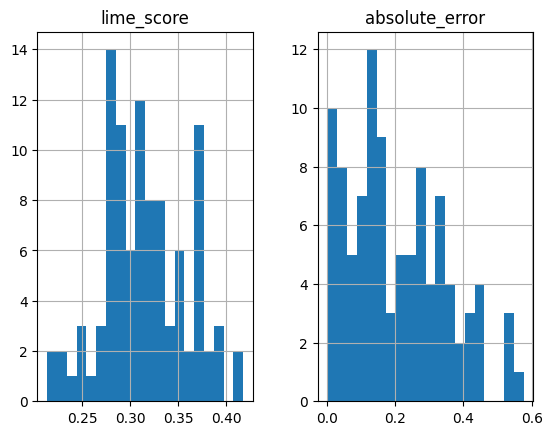

In [39]:
results[['lime_score', 'absolute_error']].hist(bins=20)